# 01 — Comprendre et préparer C-MAPSS FD001

**Objectif : passer des fichiers bruts à des entrées ML/DL reproductibles, sans fuite de données.** À la fin, nous aurons des moteurs séparés pour l'apprentissage et la validation, une cible RUL, des capteurs standardisés et des fenêtres de 30 cycles.

Ce notebook utilise uniquement `train_FD001.txt`. Le test officiel et ses réponses restent réservés au bilan final. Les chiffres affichés ci-dessous sont calculés lors de l'exécution ; aucun score de modèle n'est annoncé à cette étape.

À lire en complément : [dictionnaire physique des colonnes](../docs/DICTIONNAIRE_DONNEES.md), [audit des fichiers](../reports/DATASET_AUDIT.md). Exécuter les cellules dans l'ordre avec le noyau Python de la `.venv` du projet, après l'installation documentée dans le README.

## 1. Charger les outils et la configuration

La logique réutilisable se trouve dans `industrial_maintenance.data`. Ici, nous l'appelons étape par étape pour comprendre les décisions. Les graines, la part de validation et la longueur de fenêtre viennent du même fichier TOML que la commande de préparation.

Le répertoire du projet est retrouvé depuis le dossier courant du notebook. Nous utilisons le paquet installé dans l'environnement Python sélectionné.

In [1]:
import platform
import tomllib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from industrial_maintenance.data import (
    SENSOR_COLUMNS,
    SETTING_COLUMNS,
    SensorPreprocessor,
    add_rul,
    load_cmapss,
    make_windows,
    split_by_engine,
    truncate_validation,
)

%matplotlib inline

ROOT = next(
    (candidate for candidate in [Path.cwd(), *Path.cwd().parents]
     if (candidate / "configs" / "fd001.toml").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Ouvrir le notebook depuis le dossier du projet.")

with (ROOT / "configs" / "fd001.toml").open("rb") as stream:
    config = tomllib.load(stream)

if config["data"]["subset"] != "FD001":
    raise ValueError("Ce notebook est consacré à FD001.")

plt.rcParams.update({
    "figure.dpi": 115,
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.18,
    "figure.constrained_layout.use": True,
})
BLUE, ORANGE, GREEN = "#2463a5", "#c47727", "#24836d"

print(f"Python {platform.python_version()} | pandas {pd.__version__} | NumPy {np.__version__}")
display(config)

Python 3.12.10 | pandas 2.3.3 | NumPy 2.5.3


{'data': {'raw_dir': 'CMAPSSData', 'subset': 'FD001'},
 'split': {'validation_fraction': 0.2, 'seed': 42},
 'validation': {'seed': 43, 'min_observed_cycles': 20},
 'windows': {'length': 30},
 'output': {'directory': 'data/processed/FD001',
  'report_dir': 'reports/fd001'}}

## 2. Lire les observations et séparer les moteurs immédiatement

Chaque ligne correspond à **un moteur × un cycle**. Les cinq premières colonnes donnent l'identifiant, le cycle et trois réglages ; les 21 suivantes sont les capteurs. Le chargeur vérifie le format, l'absence de valeurs non finies, l'unicité des couples moteur/cycle et la continuité des trajectoires.

Nous réservons **20 % des moteurs** à la validation avant d'examiner les distributions des capteurs. Une séparation aléatoire des lignes laisserait des morceaux d'un même moteur dans les deux groupes, avec des historiques très semblables. La validation doit mesurer la généralisation à d'autres moteurs.

Dans la suite, `train` signifie « groupe d'apprentissage interne » et ne désigne donc pas tout le fichier officiel.

In [2]:
raw_path = ROOT / config["data"]["raw_dir"] / "train_FD001.txt"
raw = load_cmapss(raw_path)

train_raw, validation_raw = split_by_engine(
    raw,
    validation_fraction=config["split"]["validation_fraction"],
    seed=config["split"]["seed"],
)
train_ids = set(train_raw["unit_id"].unique())
validation_ids = set(validation_raw["unit_id"].unique())
assert train_ids.isdisjoint(validation_ids)
assert train_ids | validation_ids == set(raw["unit_id"].unique())

split_summary = pd.DataFrame({
    "groupe": ["apprentissage", "validation avant coupure"],
    "moteurs": [len(train_ids), len(validation_ids)],
    "observations": [len(train_raw), len(validation_raw)],
}).set_index("groupe")
display(split_summary)
print("Moteurs de validation :", sorted(validation_ids))
display(train_raw.head())
del raw

,moteurs,observations
groupe,,
apprentissage,80,16779
validation avant coupure,20,3852


Moteurs de validation : [np.int64(3), np.int64(5), np.int64(19), np.int64(22), np.int64(25), np.int64(26), np.int64(28), np.int64(34), np.int64(43), np.int64(51), np.int64(52), np.int64(53), np.int64(57), np.int64(60), np.int64(62), np.int64(72), np.int64(82), np.int64(93), np.int64(98), np.int64(100)]


,unit_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392.0,2388.0,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392.0,2388.0,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390.0,2388.0,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392.0,2388.0,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393.0,2388.0,100.0,38.90,23.4044


## 3. Construire la cible : combien de cycles restent-ils ?

Pour une trajectoire complète dont la fin de vie se situe au cycle $T_i$ :

$$y_{i,t} = \mathrm{RUL}_{i,t} = T_i - t.$$

À ce stade, la RUL est **non plafonnée**. La fin de vie connue fournit la bonne réponse pendant l'apprentissage ; elle ne deviendra jamais une variable d'entrée du modèle. Le dernier cycle d'une trajectoire complète porte la cible zéro.

Nous calculons aussi les cibles des moteurs de validation **avant** de couper leurs historiques. Calculer `max(cycle) - cycle` après la coupure attribuerait à tort zéro à leur dernière observation.

In [3]:
train = add_rul(train_raw)
validation_full = add_rul(validation_raw)

example_id = int(train["unit_id"].min())
example = train.loc[train["unit_id"].eq(example_id)].copy()
failure_cycle = int(example["cycle"].max())
example_rows = example.iloc[[0, len(example) // 2, -1]][
    ["unit_id", "cycle", "sensor_2", "sensor_11", "rul"]
]
print(f"Moteur {example_id} du groupe d'apprentissage : fin de vie au cycle {failure_cycle}.")
display(example_rows)
print("Exemple de calcul :", failure_cycle, "-", int(example_rows.iloc[1]["cycle"]),
      "=", int(example_rows.iloc[1]["rul"]), "cycles restants")
assert train.groupby("unit_id")["rul"].last().eq(0).all()

Moteur 1 du groupe d'apprentissage : fin de vie au cycle 192.


,unit_id,cycle,sensor_2,sensor_11,rul
0,1,1,641.82,47.47,191
96,1,97,642.07,47.46,95
191,1,192,643.54,48.25,0


Exemple de calcul : 192 - 97 = 95 cycles restants


## 4. Explorer la durée des trajectoires d'apprentissage

Un histogramme avec **une valeur par moteur** évite de donner mécaniquement plus de poids aux moteurs ayant davantage de lignes. Cette distribution décrit la durée *observée* jusqu'à la fin de vie, pas un âge total depuis la fabrication.

Deux moteurs peuvent atteindre la limite opérationnelle à des cycles différents. Le seul compteur de cycles ne suffit donc pas à connaître exactement leur RUL.

,cycles jusqu'à la fin de vie
count,80.000000
mean,209.737500
std,49.041637
min,128.000000
25%,179.500000
50%,199.000000
75%,231.750000
max,362.000000


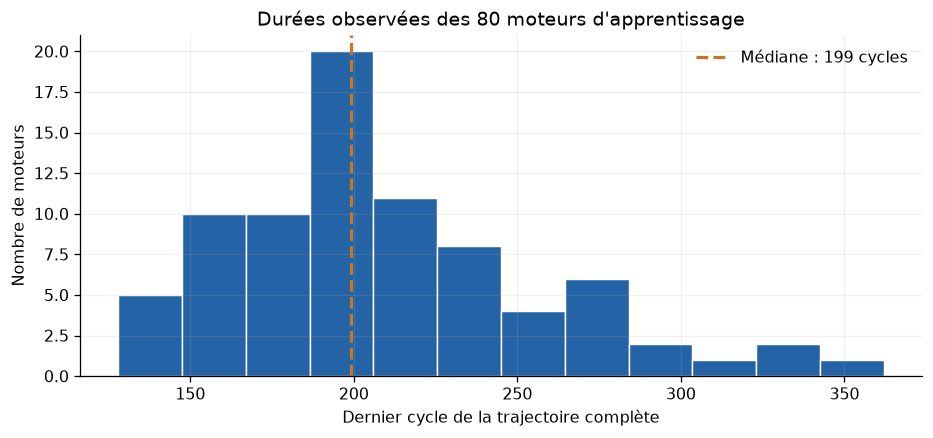

In [4]:
lifetimes = train.groupby("unit_id")["cycle"].max()
display(lifetimes.describe().rename("cycles jusqu'à la fin de vie").to_frame())

fig, ax = plt.subplots(figsize=(8, 3.7))
ax.hist(lifetimes, bins=12, color=BLUE, edgecolor="white", linewidth=0.9)
ax.axvline(lifetimes.median(), color=ORANGE, linestyle="--", linewidth=2,
           label=f"Médiane : {lifetimes.median():.0f} cycles")
ax.set(title=f"Durées observées des {len(lifetimes)} moteurs d'apprentissage",
       xlabel="Dernier cycle de la trajectoire complète", ylabel="Nombre de moteurs")
ax.legend(frameon=False)
plt.show()

## 5. Observer les trajectoires des capteurs

Nous regardons deux grandeurs documentées : `sensor_2` (T24, température totale en sortie du compresseur basse pression) et `sensor_11` (Ps30, pression statique en sortie du compresseur haute pression). Les unités sont respectivement °R et psia. [Article de référence, tableau 2](../CMAPSSData/Damage%20Propagation%20Modeling.pdf).

À gauche, les moteurs sont alignés sur leur premier cycle observé. À droite, ils sont alignés par leur **RUL réelle** : la fin de vie est au bord droit. Cet alignement utilise les cibles à des fins d'exploration du groupe d'apprentissage. Il ne constitue pas une entrée disponible lors de l'inférence.

Nous sélectionnons les quatre premiers identifiants d'apprentissage, sans choisir ceux dont les courbes seraient les plus convaincantes. Le bruit et les différences entre moteurs font partie du problème.

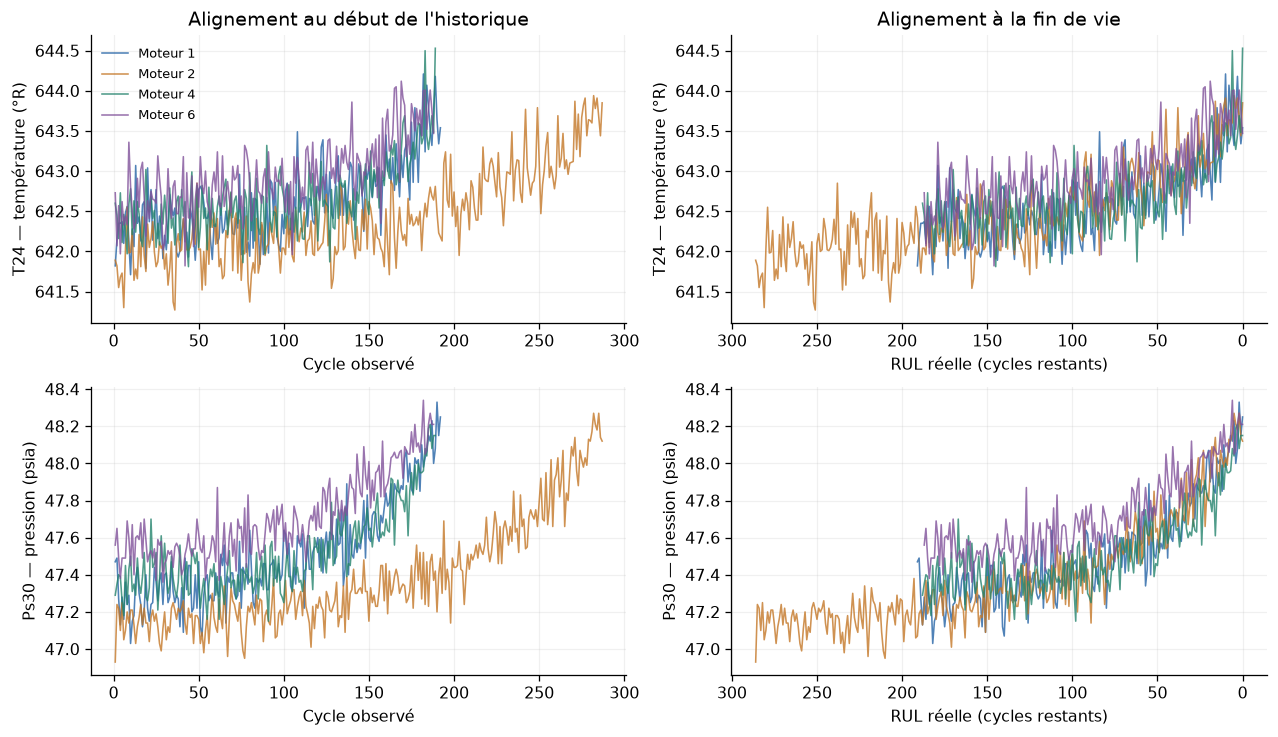

In [5]:
selected_ids = sorted(train_ids)[:4]
sensor_labels = {
    "sensor_2": "T24 — température (°R)",
    "sensor_11": "Ps30 — pression (psia)",
}
colors = [BLUE, ORANGE, GREEN, "#80519a"]

fig, axes = plt.subplots(2, 2, figsize=(11, 6.3))
for row, (sensor, label) in enumerate(sensor_labels.items()):
    for unit_id, color in zip(selected_ids, colors):
        trajectory = train.loc[train["unit_id"].eq(unit_id)]
        axes[row, 0].plot(trajectory["cycle"], trajectory[sensor],
                          color=color, alpha=0.8, linewidth=1, label=f"Moteur {unit_id}")
        axes[row, 1].plot(trajectory["rul"], trajectory[sensor],
                          color=color, alpha=0.8, linewidth=1)
    axes[row, 0].set(xlabel="Cycle observé", ylabel=label)
    axes[row, 1].set(xlabel="RUL réelle (cycles restants)", ylabel=label)
    axes[row, 1].invert_xaxis()
axes[0, 0].set_title("Alignement au début de l'historique")
axes[0, 1].set_title("Alignement à la fin de vie")
axes[0, 0].legend(frameon=False, fontsize=8)
plt.show()

## 6. Distinguer un capteur constant d'un capteur peu variable

Une colonne **exactement constante sur l'apprentissage** n'apporte aucun pouvoir de discrimination sur ce groupe. Une colonne avec deux valeurs distinctes reste différente : elle est peu variable ou quantifiée, mais n'est pas constante.

Nous calculons le nombre de valeurs distinctes et la fréquence de la valeur la plus courante. Les écarts types bruts ont des unités différentes : leur taille ne permet pas de classer directement l'utilité de capteurs de pression, de température et de vitesse.

Les trois réglages sont observés ici pour comprendre FD001, puis exclus des entrées de cette première préparation consacrée à une seule condition opératoire. Cette décision devra être réexaminée pour FD002/FD004.

In [6]:
eda_columns = [*SETTING_COLUMNS, *SENSOR_COLUMNS]
variability = pd.DataFrame({
    "valeurs_distinctes": train[eda_columns].nunique(),
    "minimum": train[eda_columns].min(),
    "maximum": train[eda_columns].max(),
    "ecart_type": train[eda_columns].std(ddof=0),
    "frequence_dominante": [
        train[name].value_counts(normalize=True).iloc[0] for name in eda_columns
    ],
})
variability["constante_exacte"] = variability["valeurs_distinctes"].eq(1)
display(variability.round(6))

constant_sensors = [
    name for name in SENSOR_COLUMNS if variability.loc[name, "constante_exacte"]
]
print("Capteurs exactement constants sur l'apprentissage :", constant_sensors)

,valeurs_distinctes,minimum,maximum,ecart_type,frequence_dominante,constante_exacte
setting_1,154,-0.0087,0.0087,0.002186,0.020800,False
setting_2,13,-0.0006,0.0006,0.000292,0.102569,False
setting_3,1,100.0000,100.0000,0.000000,1.000000,True
sensor_1,1,518.6700,518.6700,0.000000,1.000000,True
sensor_2,304,641.2100,644.5300,0.500081,0.009297,False
sensor_3,2922,1571.0400,1616.9100,6.121097,0.001311,False
sensor_4,3894,1382.2500,1441.4900,8.988405,0.001013,False
sensor_5,1,14.6200,14.6200,0.000000,1.000000,True
sensor_6,2,21.6000,21.6100,0.001391,0.980273,False
sensor_7,509,549.8500,556.0600,0.887996,0.005721,False


Capteurs exactement constants sur l'apprentissage : ['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']


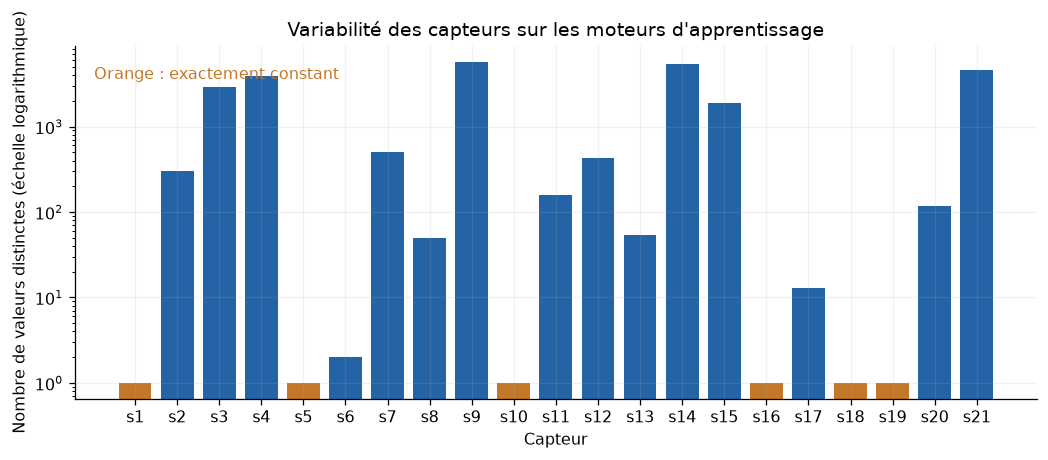

In [7]:
sensor_variability = variability.loc[list(SENSOR_COLUMNS)]
fig, ax = plt.subplots(figsize=(9, 3.8))
bar_colors = [
    ORANGE if n == 1 else BLUE
    for n in sensor_variability["valeurs_distinctes"]
]
ax.bar(np.arange(len(SENSOR_COLUMNS)),
       sensor_variability["valeurs_distinctes"],
       color=bar_colors, width=0.78)
ax.set_xticks(np.arange(len(SENSOR_COLUMNS)),
              [name.replace("sensor_", "s") for name in SENSOR_COLUMNS])
ax.set_yscale("log")
ax.set(title="Variabilité des capteurs sur les moteurs d'apprentissage",
       xlabel="Capteur", ylabel="Nombre de valeurs distinctes (échelle logarithmique)")
ax.text(0.02, 0.94, "Orange : exactement constant", transform=ax.transAxes,
        color=ORANGE, va="top")
plt.show()

## 7. Examiner les associations avec la RUL

La corrélation de Pearson décrit ici une association linéaire **sur les lignes d'apprentissage**. Nous retirons les constantes de ce calcul, car leur corrélation n'est pas définie.

Ce graphique est un diagnostic exploratoire : les lignes successives d'un moteur sont dépendantes et les moteurs longs pèsent davantage. Une corrélation élevée n'établit ni causalité ni performance sur des moteurs inconnus. Nous ne sélectionnons pas automatiquement les capteurs à partir de ce classement.

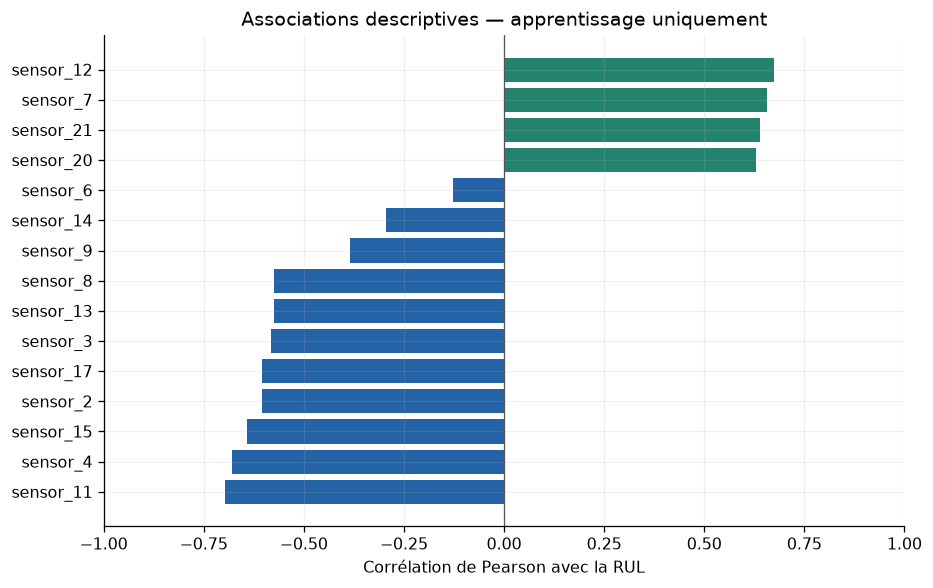

In [8]:
variable_sensors = [name for name in SENSOR_COLUMNS if name not in constant_sensors]
correlations = (
    train[[*variable_sensors, "rul"]].corr()["rul"]
    .drop("rul").sort_values()
)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(correlations.index, correlations.values,
        color=[BLUE if value < 0 else GREEN for value in correlations.values])
ax.axvline(0, color="#555555", linewidth=0.8)
ax.set(xlim=(-1, 1), xlabel="Corrélation de Pearson avec la RUL",
       title="Associations descriptives — apprentissage uniquement")
plt.show()

## 8. Simuler des historiques interrompus pour la validation

Nous disposons de la fin de vie des moteurs de validation parce qu'ils proviennent du fichier officiel d'entraînement. Pour simuler notre futur usage, nous cachons leur fin de trajectoire.

Pour chaque moteur, la coupure est tirée uniformément entre le minimum configuré (20 cycles par défaut) et `T - 1`, bornes incluses. Si un historique était plus court, la borne basse serait ramenée à `T - 1`. La graine fixe rend les coupures reproductibles.

Cette distribution de coupures est **notre choix expérimental** ; elle ne prétend pas reproduire exactement la distribution cachée du test NASA. Elle servira de protocole fixe pour comparer les modèles. Nous n'ajustons ni sélection de capteurs ni standardisation sur ces moteurs.

In [9]:
validation_observed, cutoffs = truncate_validation(
    validation_full,
    seed=config["validation"]["seed"],
    min_observed_cycles=config["validation"]["min_observed_cycles"],
)
assert cutoffs["rul"].notna().all()
assert cutoffs["rul"].gt(0).all()
assert cutoffs["cutoff_cycle"].lt(cutoffs["failure_cycle"]).all()
assert np.array_equal(
    validation_observed.groupby("unit_id")["rul"].last().to_numpy(),
    cutoffs.sort_values("unit_id")["rul"].to_numpy(),
)
display(cutoffs.head(8))
print(f"Validation : {len(cutoffs)} moteurs, {len(validation_observed)} observations visibles.")
print("La RUL de chaque dernière observation reste strictement positive.")

,unit_id,cutoff_cycle,failure_cycle,rul
0,3,100,179,79.0
1,5,182,269,87.0
2,19,75,158,83.0
3,22,27,202,175.0
4,25,141,230,89.0
5,26,23,199,176.0
6,28,60,165,105.0
7,34,166,195,29.0


Validation : 20 moteurs, 2037 observations visibles.
La RUL de chaque dernière observation reste strictement positive.


## 9. Ajuster le prétraitement sur l'apprentissage

Le préprocesseur retire uniquement les capteurs **exactement constants**, puis standardise les autres :

$$z = \frac{x - \mu_{\mathrm{train}}}{\sigma_{\mathrm{train}}}.$$

Les moyennes et écarts types sont estimés sur les lignes d'apprentissage. Nous appliquons ensuite les mêmes paramètres aux observations de validation avec `transform`. Une nouvelle estimation sur la validation ferait entrer de l'information du groupe d'évaluation dans le traitement.

`unit_id`, `cycle` et `rul` sont conservés pour l'alignement et la traçabilité, mais exclus de la matrice des caractéristiques. Les réglages sont également exclus de cette première configuration FD001. Aucun plafonnement, lissage ou imputation n'est appliqué.

Un capteur faiblement variable peut être amplifié par la standardisation. Sa suppression éventuelle constituera une expérience distincte, justifiée sur la validation.

In [10]:
preprocessor = SensorPreprocessor().fit(train)
train_scaled = preprocessor.transform(train)
validation_scaled = preprocessor.transform(validation_observed)
feature_names = list(preprocessor.feature_names_)

print(f"{len(feature_names)} capteurs conservés :", feature_names)
print("Capteurs retirés :", list(preprocessor.dropped_features_))
assert not {"unit_id", "cycle", "rul", *SETTING_COLUMNS}.intersection(feature_names)

scaling_summary = pd.DataFrame({
    "moyenne_apprise": preprocessor.scaler_.mean_,
    "echelle_apprise": preprocessor.scaler_.scale_,
    "moyenne_train_transformee": train_scaled[feature_names].mean().to_numpy(),
    "ecart_type_train_transforme": train_scaled[feature_names].std(ddof=0).to_numpy(),
}, index=feature_names)
display(scaling_summary.round(6))
display(train_scaled.head(3))

15 capteurs conservés : ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
Capteurs retirés : ['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']


,moyenne_apprise,echelle_apprise,moyenne_train_transformee,ecart_type_train_transforme
sensor_2,642.681417,0.500081,0.0,1.0
sensor_3,1590.525065,6.121097,0.0,1.0
sensor_4,1408.954104,8.988405,0.0,1.0
sensor_6,21.609803,0.001391,-0.0,1.0
sensor_7,553.366299,0.887996,0.0,1.0
sensor_8,2388.096839,0.070547,-0.0,1.0
sensor_9,9064.848749,21.033951,0.0,1.0
sensor_11,47.541259,0.267236,0.0,1.0
sensor_12,521.410873,0.738829,-0.0,1.0
sensor_13,2388.096516,0.071501,-0.0,1.0


,unit_id,cycle,rul,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21
0,1,1,191,-1.722554,-0.134790,-0.929431,0.141859,1.119038,-0.522188,-0.887078,-0.266651,0.337192,-1.070139,-0.261835,-0.602579,-0.780838,1.349578,1.192649
1,1,2,190,-1.062662,0.211553,-0.646845,0.141859,0.432098,-0.805686,-0.987867,-0.191811,1.176358,-0.370847,-0.655324,-0.274506,-0.780838,1.017804,1.235083
2,1,3,189,-0.662727,-0.414152,-0.528915,0.141859,1.006425,-0.238690,-0.566168,-1.015053,1.365847,-0.930281,-0.559297,-0.647922,-2.072343,0.741326,0.502651


## 10. Passer d'un tableau à des fenêtres temporelles

Pour une fenêtre finissant au cycle $t$, l'entrée ne contient que des observations disponibles jusqu'à $t$. La cible est la RUL à ce cycle $t$, pas celle de la dernière ligne de toute la trajectoire.

La forme de `X` sera **nombre d'exemples × 30 cycles × nombre de capteurs conservés**. Nous créons une fenêtre par observation d'apprentissage. En validation, `last_only=True` donne **une seule fenêtre et une seule cible par moteur**, à sa coupure.

Pour un historique de moins de 30 cycles, nous répétons sa première observation à gauche. Ce remplissage conserve chaque moteur et n'utilise aucun futur. Les copies ne sont pas des observations supplémentaires : `observed_lengths` conserve le nombre réel de cycles présents. Les futurs modèles devront tenir compte de cette convention ; par exemple les statistiques de la Random Forest pourront utiliser seulement la partie réellement observée.

Avec une fenêtre par ligne, un moteur long fournit plus d'exemples d'apprentissage. Cette pondération implicite est connue et pourra être comparée à un échantillonnage équilibré au jalon des modèles.

In [11]:
window_length = config["windows"]["length"]

train_windows = make_windows(
    train_scaled, feature_names, window_length=window_length
)
validation_windows = make_windows(
    validation_scaled, feature_names,
    window_length=window_length, last_only=True,
)

assert set(train_windows.unit_ids).isdisjoint(set(validation_windows.unit_ids))
assert len(validation_windows.X) == len(validation_ids)
assert np.isfinite(validation_windows.y).all()
assert (validation_windows.y > 0).all()

display(pd.DataFrame({
    "groupe": ["apprentissage", "validation"],
    "forme_X": [train_windows.X.shape, validation_windows.X.shape],
    "forme_y": [train_windows.y.shape, validation_windows.y.shape],
    "fenetres_avec_remplissage": [
        int((train_windows.observed_lengths < window_length).sum()),
        int((validation_windows.observed_lengths < window_length).sum()),
    ],
}).set_index("groupe"))

display(pd.DataFrame({
    "unit_id": validation_windows.unit_ids,
    "cycle_observe": validation_windows.end_cycles,
    "cycles_reels_dans_fenetre": validation_windows.observed_lengths,
    "cible_rul": validation_windows.y,
}).head(8))

,forme_X,forme_y,fenetres_avec_remplissage
groupe,,,
apprentissage,"(16779, 30, 15)","(16779,)",2320
validation,"(20, 30, 15)","(20,)",2


,unit_id,cycle_observe,cycles_reels_dans_fenetre,cible_rul
0,3,100,30,79.0
1,5,182,30,87.0
2,19,75,30,83.0
3,22,27,27,175.0
4,25,141,30,89.0
5,26,23,23,176.0
6,28,60,30,105.0
7,34,166,30,29.0


### Vérifier une fenêtre complète et rendre le remplissage visible

Nous inspectons une fenêtre complète du moteur d'exemple : sa dernière ligne doit coïncider avec les capteurs au cycle de fin, et sa cible avec la RUL au même instant.

Puis nous prenons **les huit premiers cycles réels** de ce même moteur. C'est une illustration supplémentaire à partir de données d'apprentissage ; elle ne modifie ni le train ni la validation préparés. Le graphique montre où se trouvent les copies et les mesures réelles dans la fenêtre.

In [12]:
window_index = int(np.flatnonzero(
    (train_windows.unit_ids == example_id)
    & (train_windows.end_cycles == window_length)
)[0])
end_cycle = int(train_windows.end_cycles[window_index])
expected_row = train_scaled.loc[
    train_scaled["unit_id"].eq(example_id)
    & train_scaled["cycle"].eq(end_cycle)
].iloc[0]

np.testing.assert_allclose(
    train_windows.X[window_index, -1],
    expected_row[feature_names].to_numpy(dtype=np.float32),
    rtol=1e-6, atol=1e-6,
)
assert train_windows.y[window_index] == expected_row["rul"]
print(f"Moteur {example_id}, cycles 1 à {end_cycle} :")
print(f"X = {train_windows.X[window_index].shape}, "
      f"cible y = {train_windows.y[window_index]:.0f} cycles restants.")

Moteur 1, cycles 1 à 30 :
X = (30, 15), cible y = 162 cycles restants.


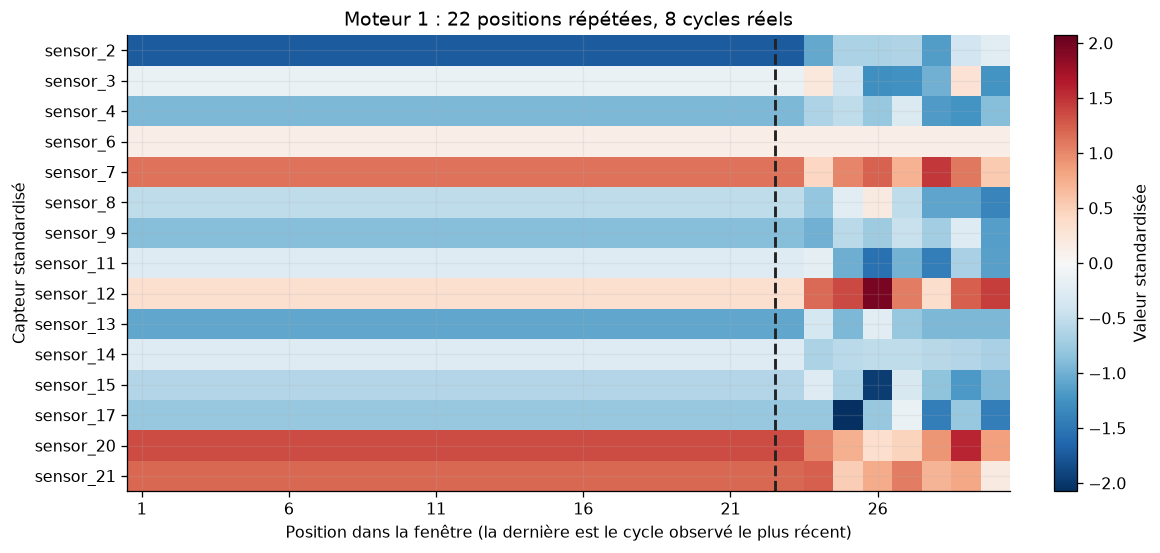

observed_lengths = 8, cycle de fin = 8, RUL cible = 184


,position,origine,sensor_2
0,1,copie du premier cycle,-1.722554
1,2,copie du premier cycle,-1.722554
2,3,copie du premier cycle,-1.722554
3,4,copie du premier cycle,-1.722554
4,5,copie du premier cycle,-1.722554
5,6,copie du premier cycle,-1.722554
6,7,copie du premier cycle,-1.722554
7,8,copie du premier cycle,-1.722554
8,9,copie du premier cycle,-1.722554
9,10,copie du premier cycle,-1.722554


In [13]:
short_history = (
    train_scaled.loc[train_scaled["unit_id"].eq(example_id)]
    .head(min(8, window_length))
)
short_window = make_windows(
    short_history, feature_names, window_length=window_length, last_only=True
)
n_real = int(short_window.observed_lengths[0])
n_padding = window_length - n_real

fig, ax = plt.subplots(figsize=(10, 4.7))
limit = max(1.0, float(np.abs(short_window.X[0]).max()))
matrix = ax.imshow(short_window.X[0].T, aspect="auto", cmap="RdBu_r",
                   vmin=-limit, vmax=limit, interpolation="nearest")
ax.set_yticks(np.arange(len(feature_names)), feature_names)
ax.set_xticks(np.arange(0, window_length, 5),
              np.arange(1, window_length + 1, 5))
if n_padding:
    ax.axvline(n_padding - 0.5, color="#222222", linestyle="--", linewidth=1.8)
ax.set(title=f"Moteur {example_id} : {n_padding} positions répétées, {n_real} cycles réels",
       xlabel="Position dans la fenêtre (la dernière est le cycle observé le plus récent)",
       ylabel="Capteur standardisé")
fig.colorbar(matrix, ax=ax, label="Valeur standardisée")
plt.show()

print(f"observed_lengths = {n_real}, cycle de fin = {short_window.end_cycles[0]}, "
      f"RUL cible = {short_window.y[0]:.0f}")
display(pd.DataFrame({
    "position": np.arange(1, window_length + 1),
    "origine": ["copie du premier cycle"] * n_padding
              + [f"cycle réel {int(c)}" for c in short_history["cycle"]],
    feature_names[0]: short_window.X[0, :, 0],
}))

## 11. Ce que nous avons établi

- La séparation par moteur précède l'exploration des capteurs et leur prétraitement.
- La RUL est calculée sur les trajectoires complètes, puis conservée lors de la coupure de validation.
- Les constantes et les paramètres de standardisation sont déterminés uniquement sur l'apprentissage.
- Chaque fenêtre appartient à un seul moteur et utilise exclusivement son passé et son présent.
- La validation produit une prédiction future par moteur, sur un historique interrompu avant sa fin de vie.
- Les historiques courts sont conservés avec une politique de remplissage explicite et une longueur réelle disponible.

Les figures permettent de formuler des hypothèses ; elles ne démontrent pas encore la qualité d'un prédicteur. **L'étape suivante** comparera une référence constante, une Random Forest sur des statistiques de fenêtres et un LSTM, avec le même découpage et les mêmes cibles de validation.

La préparation persistante des fichiers et du préprocesseur est assurée par la commande documentée dans le README :

```powershell
python -m industrial_maintenance.prepare --config configs/fd001.toml
```

Ce notebook n'écrit pas de copie concurrente des artefacts. Conserver le fichier de configuration et les coupures enregistrées pour comparer les futures expériences.